# Predikcija kategorije proizvoda na osnovu naslova

## Cilj projekta

Cilj ovog projekta je razvoj modela mašinskog učenja koji automatski predviđa kategoriju proizvoda na osnovu njegovog naziva.

U projektu ćemo analizirati podatke, očistiti ih, pripremiti tekstualne karakteristike, uporediti više modela mašinskog učenja i izabrati najbolje rešenje.

Na kraju ćemo najbolji model sačuvati i koristiti za predviđanje kategorije novih proizvoda.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import pickle

In [5]:
import pandas as pd
import numpy as np

print("Biblioteke su učitane.")

Biblioteke su učitane.


In [6]:
df = pd.read_csv("products.csv")

print("Dimenzije skupa podataka:", df.shape)

df.head()

Dimenzije skupa podataka: (35311, 8)


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


In [7]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['product ID', 'Product Title', 'Merchant ID', 'Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', 'Listing Date']


In [9]:
df = df.dropna(
    subset=["Product Title", "Category Label"]
).copy()

df["Product Title"] = df["Product Title"].astype(str).str.strip()
df["Category Label"] = df["Category Label"].astype(str).str.strip()

print("Čišćenje završeno.")

Čišćenje završeno.


In [10]:
df["title_length"] = df["Product Title"].str.len()

df["word_count"] = (
    df["Product Title"]
    .str.split()
    .str.len()
)

df["contains_number"] = (
    df["Product Title"]
    .str.contains(r"\d", regex=True)
)

print("Feature engineering završen.")

Feature engineering završen.


In [3]:
print("Kolone u skupu podataka:")
print(df.columns.tolist())

print("\nInformacije o podacima:")
df.info()

Kolone u skupu podataka:
['product ID', 'Product Title', 'Merchant ID', ' Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', ' Listing Date  ']

Informacije o podacima:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  object 
 2   Merchant ID      35311 non-null  int64  
 3    Category Label  35267 non-null  object 
 4   _Product Code    35216 non-null  object 
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7    Listing Date    35252 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.2+ MB


In [4]:
print("Nedostajuće vrednosti:")
print(df.isna().sum())

Nedostajuće vrednosti:
product ID           0
Product Title      172
Merchant ID          0
 Category Label     44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
 Listing Date       59
dtype: int64


In [7]:
print(df.columns.tolist())

['product ID', 'Product Title', 'Merchant ID', ' Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', ' Listing Date  ']


In [8]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['product ID', 'Product Title', 'Merchant ID', 'Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', 'Listing Date']


In [9]:
print("Broj različitih kategorija:")
print(df["Category Label"].nunique())

print("\nKategorije:")
print(df["Category Label"].value_counts())

Broj različitih kategorija:
13

Kategorije:
Category Label
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
Name: count, dtype: int64


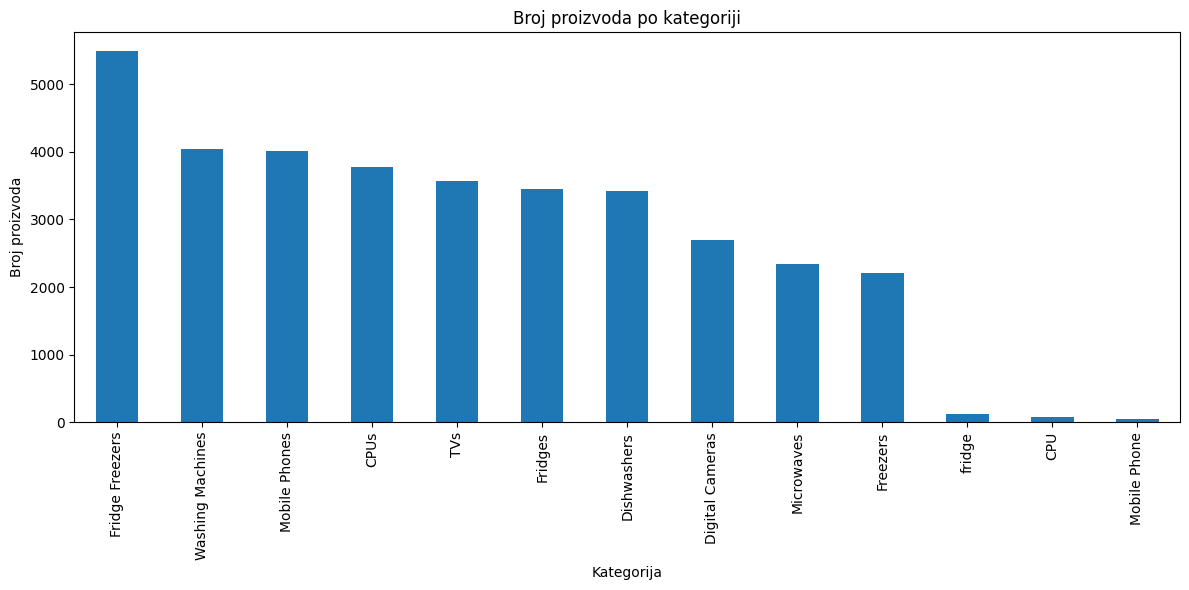

In [10]:
plt.figure(figsize=(12, 6))

df["Category Label"].value_counts().plot(kind="bar")

plt.title("Broj proizvoda po kategoriji")
plt.xlabel("Kategorija")
plt.ylabel("Broj proizvoda")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

## Čišćenje podataka

Za predikciju koristimo naziv proizvoda (`Product Title`) kao ulaznu karakteristiku, dok je `Category Label` ciljna promenljiva.

Pre treniranja modela uklanjamo redove kojima nedostaje naziv proizvoda ili kategorija. Takođe standardizujemo tekst kategorije uklanjanjem suvišnih razmaka.


In [23]:
df = df.dropna(
    subset=["Product Title", "Category Label"]
).copy()

df["Product Title"] = df["Product Title"].astype(str).str.strip()

df["Category Label"] = (
    df["Category Label"]
    .astype(str)
    .str.strip()
)

print("Broj redova nakon čišćenja:", len(df))

print("\nNedostajuće vrednosti:")
print(df[["Product Title", "Category Label"]].isna().sum())

Broj redova nakon čišćenja: 35096

Nedostajuće vrednosti:
Product Title     0
Category Label    0
dtype: int64


## Priprema podataka za model

`X` predstavlja tekstualni naziv proizvoda koji model koristi za predikciju.

`y` predstavlja kategoriju koju model treba da predvidi.


In [12]:
X = df["Product Title"]
y = df["Category Label"]

print("Broj proizvoda:", len(X))
print("Broj kategorija:", y.nunique())

Broj proizvoda: 35096
Broj kategorija: 13


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Trening skup:", len(X_train))
print("Test skup:", len(X_test))

Trening skup: 28076
Test skup: 7020


## TF-IDF vektorizacija

Pošto modeli mašinskog učenja ne mogu direktno da koriste tekst, nazive proizvoda pretvaramo u numeričke karakteristike pomoću TF-IDF metode.

Vektorizator se trenira samo na trening podacima, a zatim se ista transformacija primenjuje na test podatke.


In [14]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Trening matrica:", X_train_tfidf.shape)
print("Test matrica:", X_test_tfidf.shape)

Trening matrica: (28076, 29300)
Test matrica: (7020, 29300)


In [15]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),
    
    "Multinomial Naive Bayes": MultinomialNB(),
    
    "Linear SVC": LinearSVC(
        random_state=42
    )
}

In [16]:
results = {}

for name, model in models.items():
    print(f"Treniranje modela: {name}")
    
    model.fit(X_train_tfidf, y_train)
    
    predictions = model.predict(X_test_tfidf)
    
    results[name] = {
        "model": model,
        "predictions": predictions
    }

print("\nSvi modeli su uspešno trenirani.")

Treniranje modela: Logistic Regression
Treniranje modela: Multinomial Naive Bayes
Treniranje modela: Linear SVC

Svi modeli su uspešno trenirani.


## Evaluacija modela

Modele ćemo uporediti pomoću accuracy metrike i classification report-a.

Classification report prikazuje precision, recall i F1-score za svaku kategoriju proizvoda.


In [17]:
evaluation_results = []

for name, result in results.items():
    
    y_pred = result["predictions"]
    
    accuracy = accuracy_score(y_test, y_pred)
    
    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
    
    macro_f1 = report["macro avg"]["f1-score"]
    weighted_f1 = report["weighted avg"]["f1-score"]
    
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })
    
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

Logistic Regression
                  precision    recall  f1-score   support

             CPU       0.00      0.00      0.00        17
            CPUs       0.98      1.00      0.99       749
 Digital Cameras       0.99      0.99      0.99       538
     Dishwashers       0.98      0.91      0.95       681
        Freezers       0.99      0.92      0.96       440
 Fridge Freezers       0.90      0.96      0.93      1094
         Fridges       0.87      0.91      0.89       687
      Microwaves       0.99      0.96      0.98       466
    Mobile Phone       0.00      0.00      0.00        11
   Mobile Phones       0.95      0.99      0.97       801
             TVs       0.99      0.98      0.99       708
Washing Machines       0.96      0.95      0.95       803
          fridge       0.00      0.00      0.00        25

        accuracy                           0.95      7020
       macro avg       0.74      0.74      0.74      7020
    weighted avg       0.95      0.95      0.95   

In [18]:
results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Macro F1,Weighted F1
0,Linear SVC,0.958405,0.742408,0.954989
1,Logistic Regression,0.952422,0.737586,0.949056
2,Multinomial Naive Bayes,0.940883,0.726884,0.937337


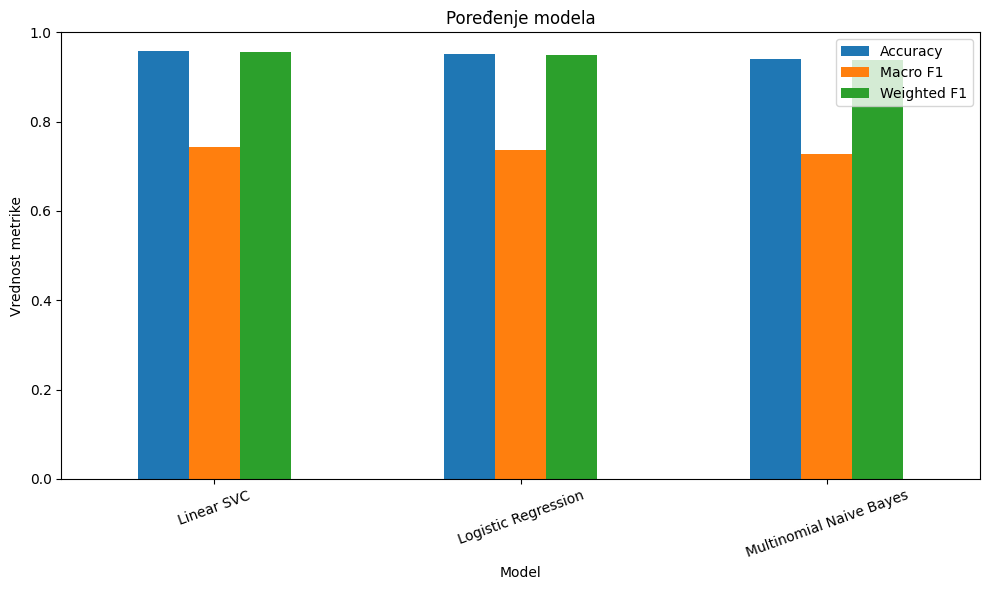

In [19]:
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Poređenje modela")
plt.ylabel("Vrednost metrike")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

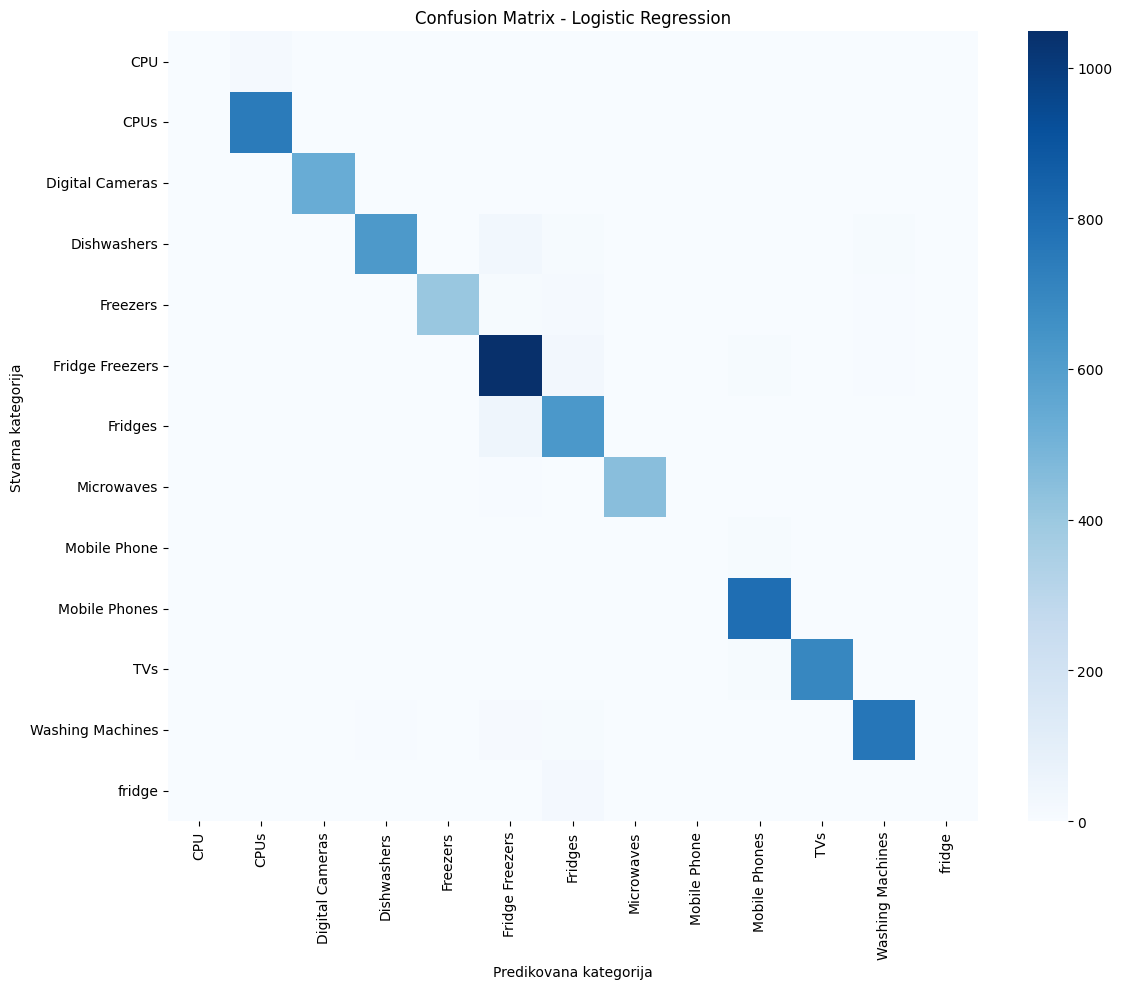

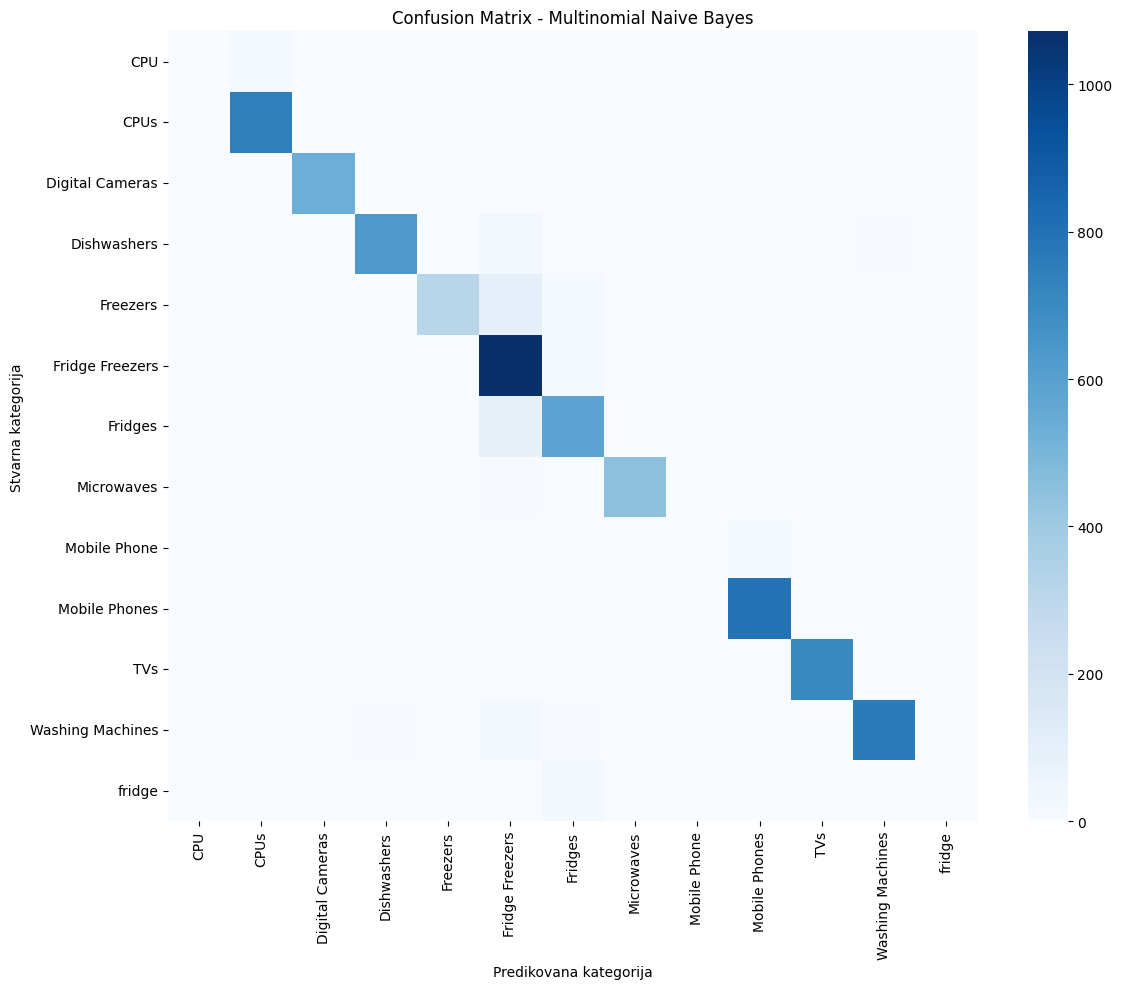

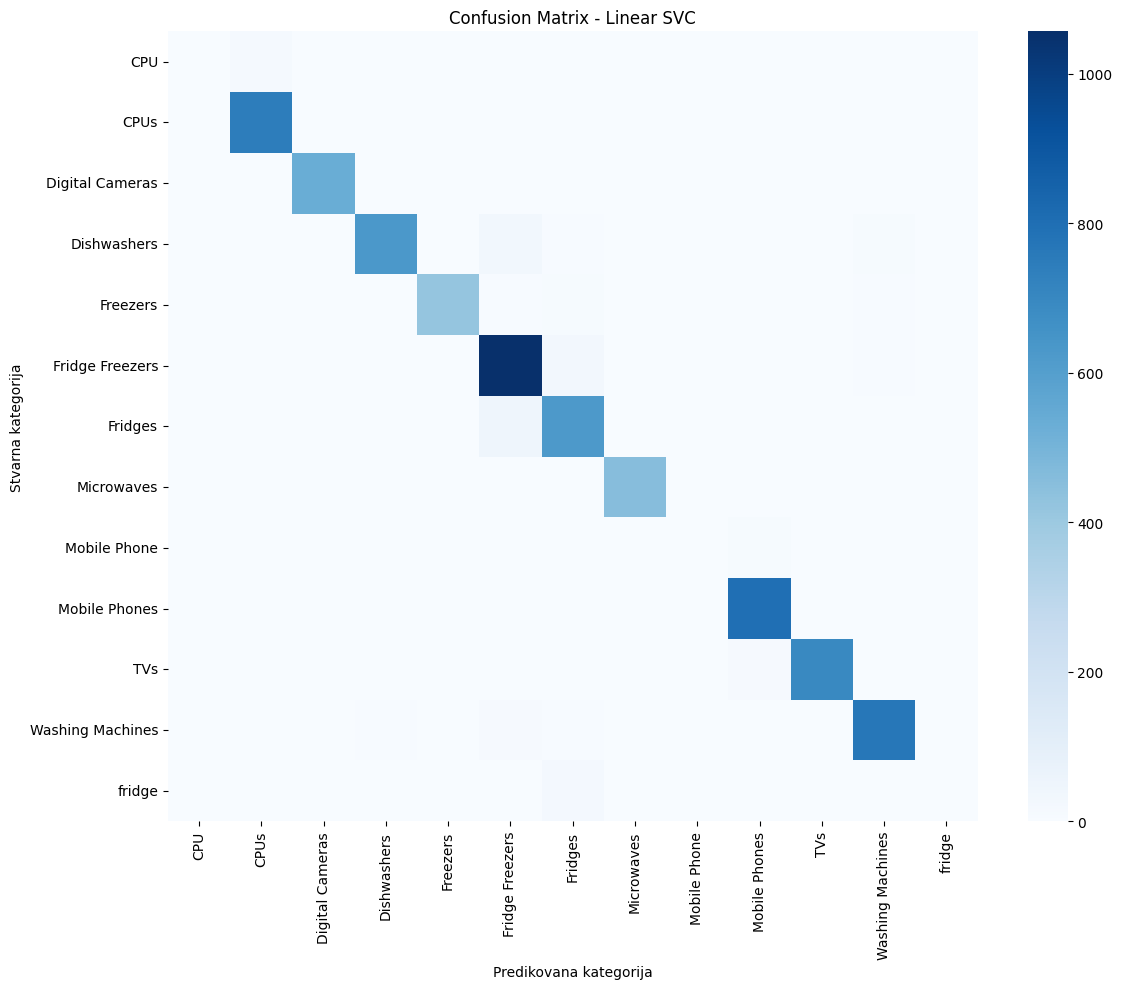

In [20]:
for name, result in results.items():
    
    y_pred = result["predictions"]
    
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=sorted(y_test.unique())
    )
    
    plt.figure(figsize=(12, 10))
    
    sns.heatmap(
        cm,
        annot=False,
        cmap="Blues",
        xticklabels=sorted(y_test.unique()),
        yticklabels=sorted(y_test.unique())
    )
    
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predikovana kategorija")
    plt.ylabel("Stvarna kategorija")
    
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    
    plt.tight_layout()
    plt.show()

## Feature engineering

Pored samog tekstualnog sadržaja, možemo posmatrati i jednostavne karakteristike naslova proizvoda.

Kreiramo broj karaktera, broj reči i informaciju o tome da li naslov sadrži broj.

Ove karakteristike mogu biti korisne jer nazivi proizvoda često sadrže modele, memoriju, veličine ili druge numeričke oznake.


In [21]:
df["title_length"] = df["Product Title"].str.len()

df["word_count"] = (
    df["Product Title"]
    .str.split()
    .str.len()
)

df["contains_number"] = (
    df["Product Title"]
    .str.contains(r"\d", regex=True)
)

df[[
    "Product Title",
    "title_length",
    "word_count",
    "contains_number"
]].head()

,Product Title,title_length,word_count,contains_number
0,apple iphone 8 plus 64gb silver,31,6,True
1,apple iphone 8 plus 64 gb spacegrau,35,7,True
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,70,13,True
3,apple iphone 8 plus 64gb space grey,35,7,True
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,54,11,True


In [22]:
results_df

,Model,Accuracy,Macro F1,Weighted F1
0,Linear SVC,0.958405,0.742408,0.954989
1,Logistic Regression,0.952422,0.737586,0.949056
2,Multinomial Naive Bayes,0.940883,0.726884,0.937337


In [24]:
from scipy.sparse import hstack
from sklearn.preprocessing import MaxAbsScaler

# Numeričke karakteristike
numeric_features = df[[
    "title_length",
    "word_count",
    "contains_number"
]].copy()

numeric_features["contains_number"] = (
    numeric_features["contains_number"].astype(int)
)

# Podela numeričkih karakteristika na trening i test
numeric_train = numeric_features.loc[X_train.index]
numeric_test = numeric_features.loc[X_test.index]

# Skaliranje
scaler = MaxAbsScaler()
numeric_train_scaled = scaler.fit_transform(numeric_train)
numeric_test_scaled = scaler.transform(numeric_test)

# Spajanje TF-IDF i novih karakteristika
X_train_combined = hstack([
    X_train_tfidf,
    numeric_train_scaled
])

X_test_combined = hstack([
    X_test_tfidf,
    numeric_test_scaled
])

print("TF-IDF matrica:", X_train_tfidf.shape)
print("Kombinovana matrica:", X_train_combined.shape)

TF-IDF matrica: (28076, 29300)
Kombinovana matrica: (28076, 29303)


In [25]:
feature_model = LinearSVC(random_state=42)

feature_model.fit(X_train_combined, y_train)

feature_predictions = feature_model.predict(X_test_combined)

feature_accuracy = accuracy_score(y_test, feature_predictions)

feature_report = classification_report(
    y_test,
    feature_predictions,
    output_dict=True,
    zero_division=0
)

feature_macro_f1 = feature_report["macro avg"]["f1-score"]
feature_weighted_f1 = feature_report["weighted avg"]["f1-score"]

print("Linear SVC sa feature engineering-om")
print("-" * 50)
print(f"Accuracy: {feature_accuracy:.6f}")
print(f"Macro F1: {feature_macro_f1:.6f}")
print(f"Weighted F1: {feature_weighted_f1:.6f}")

Linear SVC sa feature engineering-om
--------------------------------------------------
Accuracy: 0.959972
Macro F1: 0.743580
Weighted F1: 0.956609


In [11]:
import pickle
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC

X_final = df["Product Title"]
y_final = df["Category Label"]

final_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_final_tfidf = final_vectorizer.fit_transform(X_final)

final_numeric = df[
    ["title_length", "word_count", "contains_number"]
].copy()

final_numeric["contains_number"] = (
    final_numeric["contains_number"].astype(int)
)

final_scaler = MaxAbsScaler()
final_numeric_scaled = final_scaler.fit_transform(final_numeric)

X_final_combined = hstack([
    X_final_tfidf,
    final_numeric_scaled
])

final_model = LinearSVC(random_state=42)
final_model.fit(X_final_combined, y_final)

model_data = {
    "vectorizer": final_vectorizer,
    "scaler": final_scaler,
    "model": final_model
}

with open("product_category_model.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("Finalni model je uspešno sačuvan!")
print("Fajl: product_category_model.pkl")

Finalni model je uspešno sačuvan!
Fajl: product_category_model.pkl


In [12]:
predict_script = r'''
import pickle
import numpy as np
from scipy.sparse import hstack

with open("product_category_model.pkl", "rb") as file:
    model_data = pickle.load(file)

vectorizer = model_data["vectorizer"]
scaler = model_data["scaler"]
model = model_data["model"]

def extract_features(title):
    title_length = len(title)
    word_count = len(title.split())
    contains_number = int(any(char.isdigit() for char in title))
    return np.array([[title_length, word_count, contains_number]])

print("==========================================")
print(" Predikcija kategorije proizvoda")
print("==========================================")
print("Unesite 'q' za izlaz.\n")

while True:
    title = input("Unesite naslov proizvoda: ").strip()

    if title.lower() == "q":
        print("Program je završen.")
        break

    if not title:
        print("Naslov ne može biti prazan.\n")
        continue

    title_tfidf = vectorizer.transform([title])
    numeric_features = extract_features(title)
    numeric_scaled = scaler.transform(numeric_features)

    combined_features = hstack([
        title_tfidf,
        numeric_scaled
    ])

    prediction = model.predict(combined_features)[0]

    print(f"Predviđena kategorija: {prediction}\n")
'''

with open("predict_category.py", "w", encoding="utf-8") as file:
    file.write(predict_script)

print("predict_category.py je uspešno napravljen!")

predict_category.py je uspešno napravljen!


In [13]:
train_script = r'''
import pandas as pd
import pickle
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC

print("Učitavanje podataka...")

df = pd.read_csv("products.csv")
df.columns = df.columns.str.strip()

df = df.dropna(
    subset=["Product Title", "Category Label"]
).copy()

df["Product Title"] = df["Product Title"].astype(str).str.strip()
df["Category Label"] = df["Category Label"].astype(str).str.strip()

df["title_length"] = df["Product Title"].str.len()
df["word_count"] = df["Product Title"].str.split().str.len()
df["contains_number"] = df["Product Title"].str.contains(
    r"\d", regex=True
)

X = df["Product Title"]
y = df["Category Label"]

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = vectorizer.fit_transform(X)

numeric_features = df[[
    "title_length",
    "word_count",
    "contains_number"
]].copy()

numeric_features["contains_number"] = (
    numeric_features["contains_number"].astype(int)
)

scaler = MaxAbsScaler()
numeric_scaled = scaler.fit_transform(numeric_features)

X_combined = hstack([
    X_tfidf,
    numeric_scaled
])

model = LinearSVC(random_state=42)
model.fit(X_combined, y)

model_data = {
    "vectorizer": vectorizer,
    "scaler": scaler,
    "model": model
}

with open("product_category_model.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("==========================================")
print("Model je uspešno istreniran!")
print("Sačuvan je kao product_category_model.pkl")
print("Broj proizvoda:", len(df))
print("Broj kategorija:", y.nunique())
print("==========================================")
'''

with open("train_model.py", "w", encoding="utf-8") as file:
    file.write(train_script)

print("train_model.py je uspešno napravljen!")

train_model.py je uspešno napravljen!


In [15]:
readme = """# Predikcija kategorije proizvoda na osnovu naslova

## Opis projekta

Cilj projekta je automatska predikcija kategorije proizvoda na osnovu njegovog naslova.

Korišćen je skup podataka products.csv sa više od 30.000 proizvoda.

## Korišćeni modeli

Testirana su tri algoritma:

- Logistic Regression
- Multinomial Naive Bayes
- Linear SVC

Najbolji rezultat ostvario je Linear SVC.

## Feature engineering

Korišćene su sledeće karakteristike:

- TF-IDF reprezentacija teksta
- dužina naslova proizvoda
- broj reči u naslovu
- informacija da li naslov sadrži broj

## Rezultati

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Linear SVC | 0.958405 | 0.742408 | 0.954989 |
| Logistic Regression | 0.952422 | 0.737586 | 0.949056 |
| Multinomial Naive Bayes | 0.940883 | 0.726884 | 0.937337 |

### Linear SVC sa feature engineering-om

- Accuracy: 0.959972
- Macro F1: 0.743580
- Weighted F1: 0.956609

## Pokretanje

Za treniranje modela:

python3 train_model.py

Za predikciju kategorije:

python3 predict_category.py

## Struktura projekta

- products.csv
- product_category_model.ipynb
- product_category_model.pkl
- train_model.py
- predict_category.py
- README.md
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md je uspešno napravljen!")

README.md je uspešno napravljen!
